In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import pandas_datareader as pdr
import statsmodels.api as sm

# Data Preparation

Get S&P 500 and USD series to use alongside the CSV data for monthly WIG20 quotes. Sort the indices and comute the percent returns.

In [2]:
usd = pdr.get_data_fred('DTWEXBGS', start='2006-01-01', end='2026-01-31').resample('MS').last()
usd_avg = pdr.get_data_fred('TWEXBGSMTH', start='2006-01-01', end='2026-01-31')['TWEXBGSMTH']
sp500 = yf.download('^GSPC', start='2006-01-01', end='2026-01-31', interval='1mo')

usd.index = pd.to_datetime(usd.index)
usd = usd.sort_index(ascending=True)

sp500.index = pd.to_datetime(sp500.index)
sp500 = sp500.sort_index(ascending=True)

[*********************100%***********************]  1 of 1 completed


In [3]:
wig20 = pd.read_csv('data/wig20.csv')
wig20['Date'] = pd.to_datetime(wig20['Date'], format='%m/%d/%Y')
wig20.set_index('Date', inplace=True)
wig20 = wig20.sort_index(ascending=True)
wig20['Price'] = wig20['Price'].str.replace(',', '').astype(float)

In [4]:
usd = usd['DTWEXBGS'].pct_change().loc['01-01-2007':,]
sp500 = sp500['Close'].pct_change().loc['01-01-2007':,]
wig20 = wig20['Price'].pct_change().loc['01-01-2007':,]

# Full Sample Regressions

For S&P 500 and WIG20 denoted as $y_1$ and $y_2$ respectively and $\Delta$ denoting percent changes, compute the regression:

$$\Delta y_i = \alpha_i + \beta_i \Delta\text{USD} + \varepsilon_i \, \forall i \in \{1, 2\}$$

This is the complete sample regression and will give $\beta$ coefficients describing end-to-end reaction of the indices per unit (%) change in USD returns.

In [5]:
mod_sp500 = sm.OLS(sp500, sm.add_constant(usd)).fit()
res_sp500 = mod_sp500.get_robustcov_results(cov_type='HAC', maxlags=12)
print(res_sp500.summary())

                            OLS Regression Results                            
Dep. Variable:                  ^GSPC   R-squared:                       0.361
Model:                            OLS   Adj. R-squared:                  0.358
Method:                 Least Squares   F-statistic:                     65.90
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           3.00e-14
Time:                        21:00:27   Log-Likelihood:                 439.75
No. Observations:                 229   AIC:                            -875.5
Df Residuals:                     227   BIC:                            -868.6
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0095      0.003      3.649      0.0

In [6]:
mod_wig20 = sm.OLS(wig20, sm.add_constant(usd)).fit()
res_wig20 = mod_wig20.get_robustcov_results(cov_type='HAC', maxlags=12)
print(res_wig20.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.302
Model:                            OLS   Adj. R-squared:                  0.299
Method:                 Least Squares   F-statistic:                     58.77
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           5.13e-13
Time:                        21:00:27   Log-Likelihood:                 358.29
No. Observations:                 229   AIC:                            -712.6
Df Residuals:                     227   BIC:                            -705.7
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0038      0.003      1.115      0.2

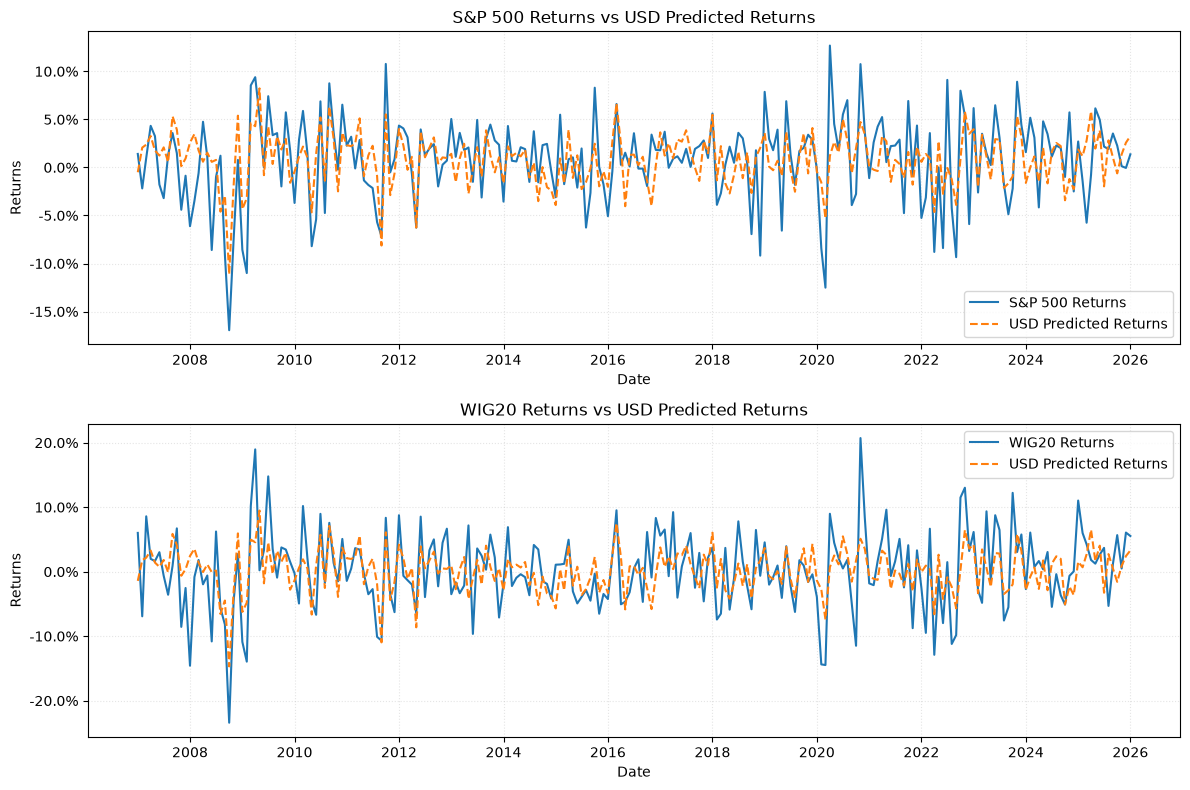

In [7]:
yhat_sp500 = res_sp500.predict(sm.add_constant(usd))
yhat_wig20 = res_wig20.predict(sm.add_constant(usd))

pct_fmt = lambda x, pos: '{:.1f}%'.format(x * 100)

fig, axs = plt.subplots(2, 1, figsize=(12, 8))

for i, data in enumerate([("S&P 500", sp500, yhat_sp500), ("WIG20", wig20, yhat_wig20)]):
    ax = axs[i]
    ax.plot(data[1].index, data[1], label=f'{data[0]} Returns')
    ax.plot(data[1].index, data[2], label='USD Predicted Returns', linestyle='--')
    ax.set_title(f'{data[0]} Returns vs USD Predicted Returns')
    ax.set_xlabel('Date')
    ax.set_ylabel('Returns')
    ax.yaxis.set_major_formatter(plt.FuncFormatter(pct_fmt))
    ax.grid(alpha=0.33, linestyle=':')
    ax.legend()

plt.tight_layout()
plt.show()

## Interpretation of $\beta$ coefficients

Without going into the regression diagnostics themselves, both results yield jointly significant regressors and individually significant $\beta$ coefficients.
The response of each equity index for a percent change in USD is as follows:

| Index | Interpretation |
|-------|-------------------|
| S&P 500 | $\Delta\text{USD} = 1\% \rightarrow \Delta\text{S\&P} = -1.5069\% $ |
| WIG20 | $\Delta\text{USD} = 1\% \rightarrow \Delta\text{WIG} = -1.8841\%$ |

Both indices respond negatively to changes in USD, however there's a notable difference in the magnitude of the response. The regression only establishes association and any specific interpretation of the relationship or causality would be speculation for the given data. However, the indices denominated in their respective currencies (USD and PLN) show that the full-sample reaction of the EM sample (WIG20) is more sensitive.

# Strong and Weak Dollar Regimes

Classify month $t$ as a strong-dollar month when the broad dollar index rose over the twelve months ending at $t-1$:

$$D_t = \mathbb{1}_{\big\lbrace\frac{\text{USD}_{t-1}}{\text{USD}_{t-13}} - 1 > 0\big\rbrace}$$

In [8]:
# Month-end data is noisy can regimes do not persist meaningfully. 
# Computing trailing 12 from the average gives a better represetnation of the episodes.
regimes = pd.DataFrame({
    'usd_ret': usd,
    'level': usd_avg.reindex(usd.index),
    'trend12': usd_avg.pct_change(12).shift(1).reindex(usd.index),
}).dropna()
regimes['strong'] = regimes['trend12'] > 0
regimes['episode'] = (regimes['strong'] != regimes['strong'].shift()).cumsum()

runs = regimes.groupby('episode').agg(strong=('strong', 'first'), months=('strong', 'size'))
by_regime, by_episode = regimes.groupby('strong'), runs.groupby('strong')

split = pd.DataFrame({
    'months': by_regime.size(),
    'share': by_regime.size() / len(regimes),
    'episodes': by_episode.size(),
    'median_run': by_episode['months'].median(),
    'max_run': by_episode['months'].max(),
}).rename(index={True: 'Strong dollar', False: 'Weak dollar'})

print(split.round(3))

               months  share  episodes  median_run  max_run
strong                                                     
Weak dollar        91  0.399        12         7.5       21
Strong dollar     137  0.601        11        12.0       35


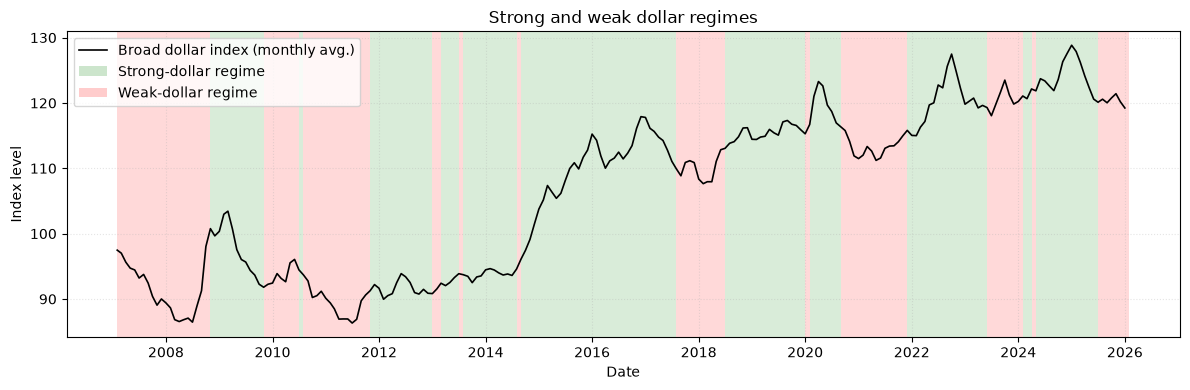

In [9]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(regimes.index, regimes['level'], color='black', lw=1.2, label='Broad dollar index (monthly avg.)')

for _, g in regimes[regimes['strong']].groupby('episode'):
    ax.axvspan(g.index[0], g.index[-1] + pd.offsets.MonthBegin(1), color='green', alpha=0.15, lw=0)
ax.axvspan(regimes.index[0], regimes.index[0], color='green', alpha=0.2, lw=0, label='Strong-dollar regime')

for _, g in regimes[~regimes['strong']].groupby('episode'):
    ax.axvspan(g.index[0], g.index[-1] + pd.offsets.MonthBegin(1), color='red', alpha=0.15, lw=0)
ax.axvspan(regimes.index[0], regimes.index[0], color='red', alpha=0.2, lw=0, label='Weak-dollar regime')

ax.set_title('Strong and weak dollar regimes')
ax.set_xlabel('Date')
ax.set_ylabel('Index level')
ax.grid(alpha=0.33, linestyle=':')
ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

# Regime-Interacted Regressions

Using $D$ as a indicator, both regressions are re-estimated with regime aware interaction terms:

$$\Delta y_i = \alpha_i + \beta_{i, 0} D + \beta_{i, 1} \Delta\text{USD} + \beta_{i, 2} \left(D \cdot \Delta\text{USD}\right) + \varepsilon_i$$

Additionally, the regime-aware sensitivity of WIG20 to S&P 500 is estimated by appending the same main effect and interaction terms for $\Delta\text{S\&P}$:

$$\Delta\text{WIG} = \alpha + \beta_0 D + \beta_1 \Delta\text{S\&P} + \beta_2 \left(D \cdot \Delta\text{S\&P}\right) + \beta_3 \Delta\text{USD} + \beta_4 \left(D \cdot \Delta\text{USD}\right) + \varepsilon$$


In [56]:
reg = regimes[['usd_ret', 'strong']]
reg['sp500'] = sp500.reindex(reg.index)
reg['wig20'] = wig20.reindex(reg.index)

D = reg['strong'].astype(float)


def interacted(y, regressors):
    X = pd.DataFrame({'const': 1.0, 'D': D}, index=reg.index)
    for nm, x in regressors.items():
        X[nm], X['D_' + nm] = x, D * x
    return sm.OLS(y, X).fit().get_robustcov_results(cov_type='HAC', maxlags=12), X


specs = {
    'S&P 500 ~ USD': interacted(reg['sp500'], {'usd': reg['usd_ret']}),
    'WIG20 ~ USD': interacted(reg['wig20'], {'usd': reg['usd_ret']}),
    'WIG20 ~ S&P 500 + USD': interacted(reg['wig20'], {'sp500': reg['sp500'], 'usd': reg['usd_ret']}),
}


def column(res, X, label):
    coefs = {nm: f'{res.params[i]:+.4f} ({res.pvalues[i]:.2f})' for i, nm in enumerate(X.columns)}
    return pd.Series({**coefs, 'R^2': f'{res.rsquared:.3f}'}, name=label)


order = ['const', 'D', 'usd', 'D_usd', 'sp500', 'D_sp500', 'R^2']
table = pd.concat([column(res, X, k) for k, (res, X) in specs.items()], axis=1).reindex(order).fillna('')

print('Coefficient (p-value) + R^2:\n')
print(table.to_string(col_space=[0,25,25], justify='center'))

Coefficient (p-value) + R^2:

         S&P 500 ~ USD         WIG20 ~ USD          WIG20 ~ S&P 500 + USD  
const    +0.0073 (0.13)       +0.0010 (0.88)            -0.0052 (0.17)     
D        +0.0034 (0.50)       +0.0042 (0.55)            +0.0032 (0.52)     
usd      -1.5887 (0.00)       -1.9697 (0.00)            -0.6276 (0.01)     
D_usd    +0.1372 (0.60)       +0.1319 (0.70)            -0.2477 (0.49)     
sp500                                                   +0.8448 (0.00)     
D_sp500                                                 -0.1816 (0.31)     
R^2               0.364                0.308                     0.493     


In [59]:
print('\n\nJoint test that all regime terms are zero (Robust Wald):\n')
for k, (res, X) in specs.items():
    terms = [c for c in X.columns if c == 'D' or c.startswith('D_')]
    wt = res.wald_test(', '.join(f'{c} = 0' for c in terms), use_f=False, scalar=True)
    print(f' {k:24s} chi2({len(terms)}) = {wt.statistic:6.3f}   p = {wt.pvalue:.3f}')



Joint test that all regime terms are zero (Robust Wald):

 S&P 500 ~ USD            chi2(2) =  0.839   p = 0.657
 WIG20 ~ USD              chi2(2) =  0.609   p = 0.738
 WIG20 ~ S&P 500 + USD    chi2(3) =  1.182   p = 0.757


The regressions $\Delta\text{S\&P}$ and $\Delta\text{WIG}$ both display that the $D\cdot\Delta\text{USD}$ interaction term and the main effect $D$ are insignificant. Similar to the above regressions without regime-awareness, the $\Delta\text{USD}$ remains significant. The added sepcification regressing $\Delta\text{WIG}$ on $\Delta\text{S\&P}$ and $\Delta\text{USD}$ also confirms that regime awareness does not add explanatory power to the model both for interactions on the S&P 500 and USD returns. Main effects on both S&P 500 and USD returns are significant. Moreover, the joint Wald test with $H_0: \beta_{\text{interaction}} = 0$ fail to reject the null by a wide margin.


The diversification case for a US investor wanting to invest in the WIG20 is weak for this sample. The regression betas, directionality, and regime-invariance all support that the WIG20 does not mitigate USD exposure in the sample period. Looking at the regression coefficients with and without regime awareness, WIG20's response to USD movements turn out larger and equidirectional to that of S&P 500's.